# Analisi avanzate

* Importiamo le librerie 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import numpy as np
import scipy.stats as stats

* Ricarichiamo il dataframe ricordandoci di trasformare il dtype corretto

In [2]:
df_avanzato = pd.read_csv(r'Dati\puliti\Unione_dati.csv', sep=';', low_memory=False)
df_avanzato.head()

,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,Codice Ripartizione geografica,Codice Regione,Codice Provincia (Storico),Codice Provincia/Uts,Codice Comune (alfanumerico),...,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente)
0,1001,KILLINJ,Feriti,2001,10,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
1,1001,KILLINJ,Feriti,2002,10,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
2,1001,KILLINJ,Feriti,2003,7,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
3,1001,KILLINJ,Feriti,2004,13,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
4,1001,KILLINJ,Feriti,2005,2,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0


In [3]:
df_avanzato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 592635 entries, 0 to 592634
Data columns (total 22 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   REF_AREA                        592635 non-null  int64  
 1   DATA_TYPE                       592635 non-null  object 
 2   RESULT                          592635 non-null  object 
 3   TIME_PERIOD                     592635 non-null  int64  
 4   OBS_VALUE                       592635 non-null  int64  
 5   Codice Ripartizione geografica  592635 non-null  float64
 6   Codice Regione                  592635 non-null  float64
 7   Codice Provincia (Storico)      592635 non-null  float64
 8   Codice Provincia/Uts            592635 non-null  float64
 9   Codice Comune (alfanumerico)    592635 non-null  int64  
 10  Codice Comune (numerico)        592635 non-null  float64
 11  Comune                          592635 non-null  object 
 12  Comune (dizione 

In [4]:
df_avanzato['Superficie (Kmq)'] = pd.to_numeric(df_avanzato['Superficie (Kmq)'].str.replace(',', '.'), errors='coerce')
df_avanzato['Popolazione residente'] = df_avanzato['Popolazione residente'].astype('Int64')

* Ricalcoliamo dei valori di incidenti per Kmq e per 1000 abitanti.

In [5]:
df_avanzato = df_avanzato[(df_avanzato['Superficie (Kmq)'] > 0) & (df_avanzato['Popolazione residente'] > 0)]
df_avanzato['incidenti_per_Kmq'] = df_avanzato['OBS_VALUE'] / df_avanzato['Superficie (Kmq)']
df_avanzato['incidenti_per_1000_Abitanti'] = (df_avanzato['OBS_VALUE'] / df_avanzato['Popolazione residente']) * 1000
print(df_avanzato[['Superficie (Kmq)', 'Popolazione residente', 'OBS_VALUE', 'incidenti_per_Kmq', 'incidenti_per_1000_Abitanti', ]].head())

   Superficie (Kmq)  Popolazione residente  OBS_VALUE  incidenti_per_Kmq  \
0           13.1463                   2585         10           0.760670   
1           13.1463                   2585         10           0.760670   
2           13.1463                   2585          7           0.532469   
3           13.1463                   2585         13           0.988871   
4           13.1463                   2585          2           0.152134   

   incidenti_per_1000_Abitanti  
0                     3.868472  
1                     3.868472  
2                      2.70793  
3                     5.029014  
4                     0.773694  


* Visualizzo il grafico di correlazione tra valori osservati = incidenti e popolazione residente solo per l'anno 2024 e solo per gli incidenti 

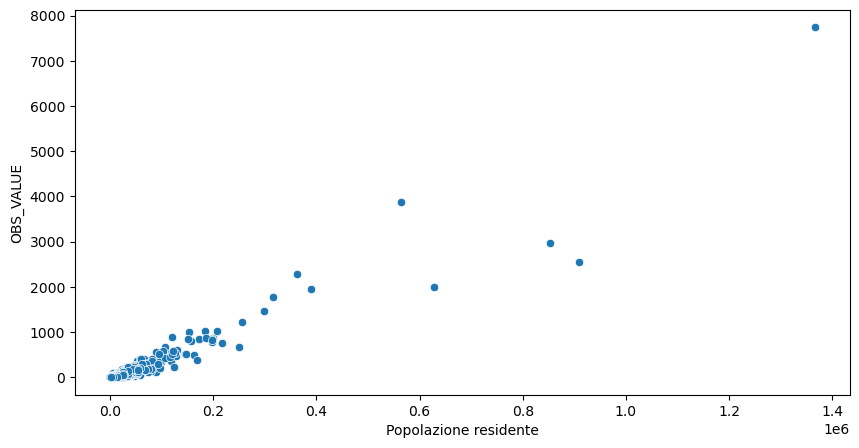

In [6]:
data= df_avanzato[(df_avanzato['TIME_PERIOD'] == 2024) & (df_avanzato['OBS_VALUE'] > 0) & (df_avanzato['RESULT'] == 'Incidenti')]
plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='Popolazione residente', y='OBS_VALUE') 
plt.show()

* Calcoliamo la correlazione

In [7]:
df_solo_incidenti = df_avanzato[df_avanzato['RESULT'] == 'Incidenti']
correl = df_solo_incidenti['Popolazione residente'].corr(df_solo_incidenti['OBS_VALUE'])
print('Coefficiente di correlazione tra Popolazione e Incidenti:', round(correl, 2))

Coefficiente di correlazione tra Popolazione e Incidenti: 0.89


* calcoliamo intercetta e slope

In [8]:
model = LinearRegression()
model.fit(data[['Popolazione residente']], data['OBS_VALUE'])
intercept = model.intercept_
slope = model.coef_[0]
print('Intercept:', intercept)
print('Slope:', slope)

Intercept: -13.51217873480299
Slope: 0.004463860232927817


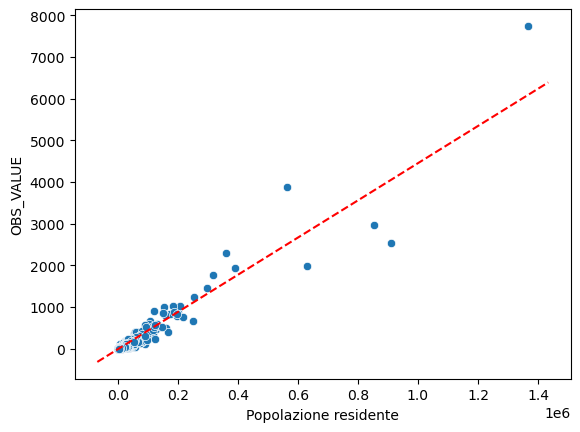

In [9]:
sns.scatterplot(x='Popolazione residente', y='OBS_VALUE', data=data)
intercept = -13.512178734802955
slope =  0.004463860232927813
axes = plt.gca()
x_vals = np.array(axes.get_xlim())
y_vals = intercept + slope * x_vals
plt.plot(x_vals, y_vals, '--', color='r')
plt.show()

* Procediamo a vedere se c'è un grafico adatto al cloustering

In [10]:
t = df_avanzato[(df_avanzato['TIME_PERIOD'] == 2024) & (df_avanzato['RESULT'] == 'Incidenti')]

In [11]:
t.head()

,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,Codice Ripartizione geografica,Codice Regione,Codice Provincia (Storico),Codice Provincia/Uts,Codice Comune (alfanumerico),...,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente),incidenti_per_Kmq,incidenti_per_1000_Abitanti
73,1001,ROADACC,Incidenti,2024,2,1.0,1.0,1.0,201.0,1001,...,0.0,0.0,2562.0,2021.0,13.1463,2024.0,2585,2024.0,0.152134,0.773694
148,1002,ROADACC,Incidenti,2024,5,1.0,1.0,1.0,201.0,1002,...,0.0,0.0,3660.0,2021.0,15.7393,2024.0,3695,2024.0,0.317676,1.35318
221,1003,ROADACC,Incidenti,2024,1,1.0,1.0,1.0,201.0,1003,...,0.0,0.0,467.0,2021.0,46.3316,2024.0,463,2024.0,0.021584,2.159827
295,1004,ROADACC,Incidenti,2024,4,1.0,1.0,1.0,201.0,1004,...,0.0,0.0,1637.0,2021.0,11.7397,2024.0,1624,2024.0,0.340724,2.463054
424,1006,ROADACC,Incidenti,2024,2,1.0,1.0,1.0,201.0,1006,...,0.0,0.0,6331.0,2021.0,17.8741,2024.0,6297,2024.0,0.111894,0.317612


In [12]:
t.shape

(6338, 24)

* calcoliamo la densità 

In [13]:
t = t.copy()
t['densita'] = t['Popolazione residente'] / t['Superficie (Kmq)']

* Mettiamo un filtro eliminando quindi i paesini piccoli che alzano il tasso

In [14]:
t = t[t['Popolazione residente'] > 10000]
t.shape

(1201, 25)

* Normalizziamo il dato per ogni colonna, il valore più basso diventa 0, il più alto diventa 1, e tutti gli altri finiscono in mezzo in proporzione infine vediamo come si presenta graficamente 

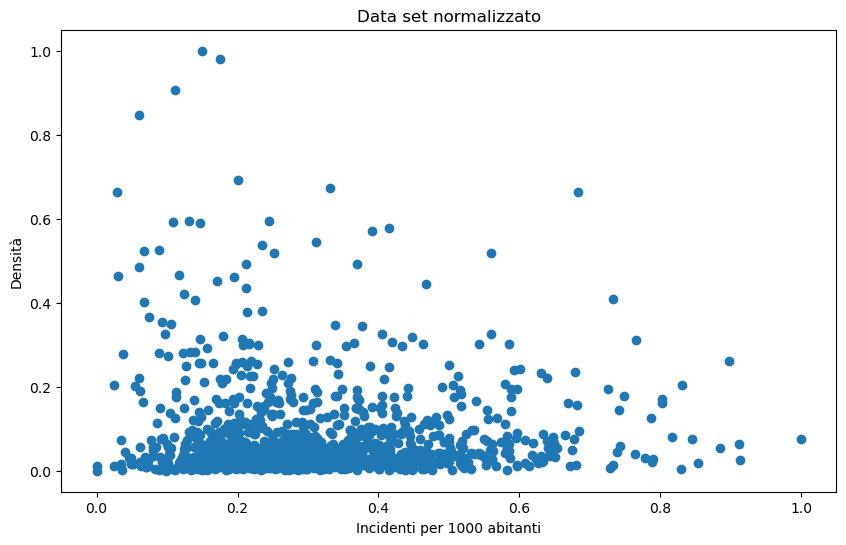

In [15]:
cols = ['incidenti_per_1000_Abitanti', 'incidenti_per_Kmq', 'densita']
scale_norm = MinMaxScaler()
scaled_dataframe = pd.DataFrame(scale_norm.fit_transform(t[cols]), columns=cols)
plt.figure(figsize=(10, 6))
plt.scatter(scaled_dataframe["incidenti_per_1000_Abitanti"], scaled_dataframe["densita"], marker="o")
plt.title('Data set normalizzato')
plt.xlabel('Incidenti per 1000 abitanti')
plt.ylabel('Densità')
plt.show()

* Utilizziamo la tecnica del gomito per capire quanti clouster prendere

c:\Users\furia\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\furia\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\furia\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\furia\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

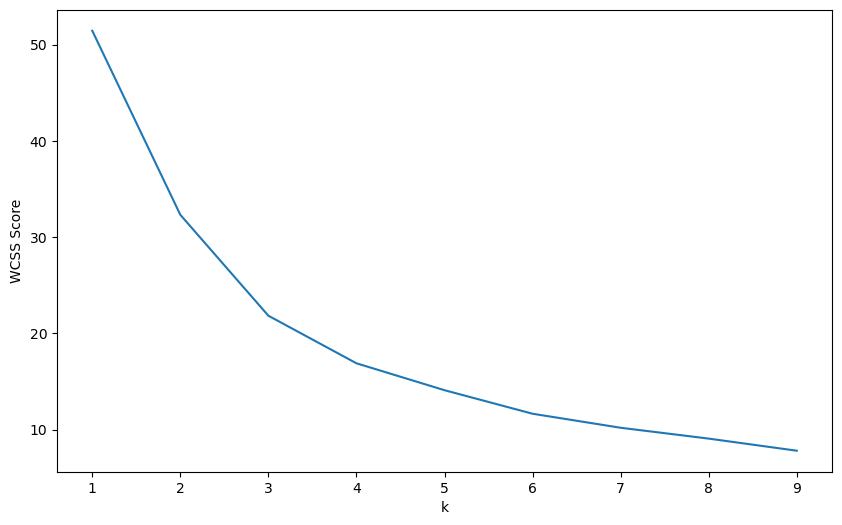

In [16]:
k_values = list(range(1, 10))
wcss_list = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_dataframe)
    wcss_list.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.xlabel("k")
plt.ylabel("WCSS Score")
plt.show()

In [17]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(scaled_dataframe)
scaled_dataframe["cluster"] = kmeans.labels_
t["cluster"] = kmeans.labels_

c:\Users\furia\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


* Visualizziomi i centroidi (la media dei valori) dei 3 clouster

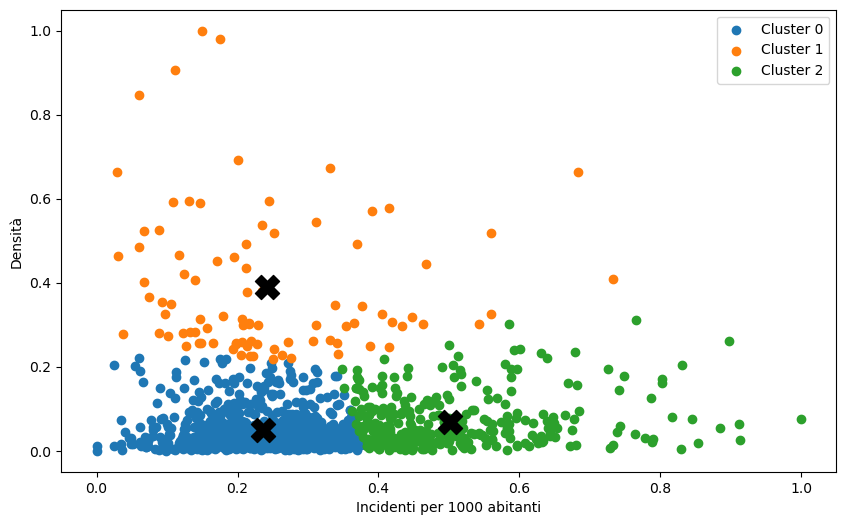

In [18]:
centroids = kmeans.cluster_centers_
plt.figure(figsize=(10, 6))
for cluster, data in scaled_dataframe.groupby("cluster"):
    plt.scatter(data["incidenti_per_1000_Abitanti"], data["densita"], label=f"Cluster {cluster}")
    plt.scatter(centroids[cluster, 0], centroids[cluster, 2], marker="X", color="black", s=300)
plt.xlabel("Incidenti per 1000 abitanti")
plt.ylabel("Densità")
plt.legend()
plt.show()

Visualizziamo l'affidabilità del cloustering con il silhouette score e il calinski harabasz score

In [19]:
print("Silhouette:", silhouette_score(scaled_dataframe[cols], scaled_dataframe["cluster"]))
print("Calinski-Harabasz:", calinski_harabasz_score(scaled_dataframe[cols], scaled_dataframe["cluster"]))

Silhouette: 0.4816636240974145
Calinski-Harabasz: 812.008970968535


* Vediamo come sono suddivisi i clouster

In [20]:
t['cluster'].value_counts()

cluster
0    770
2    341
1     90
Name: count, dtype: int64

* Nel primo clouster vediamo città metropolitane a bassa densità

In [21]:
t[t['cluster'] == 0].sort_values('incidenti_per_1000_Abitanti', ascending=False)[['Comune', 'Popolazione residente', 'incidenti_per_1000_Abitanti']].head(10)

,Comune,Popolazione residente,incidenti_per_1000_Abitanti
328813,San Miniato,27831,3.161942
446563,Conversano,25938,3.161385
451366,Francavilla Fontana,34550,3.154848
238675,Belluno,35543,3.151113
446413,Castellana Grotte,19697,3.147687
338104,Corciano,21623,3.1448
497380,Cinisi,12156,3.126028
51325,Savigliano,21792,3.120411
442216,Cerignola,56900,3.110721
295759,Codigoro,10938,3.108429


* Nel secondo clouster vediamo città urbane densamente abitate 

In [22]:
t[t['cluster'] == 1].sort_values('incidenti_per_1000_Abitanti', ascending=False)[['Comune', 'Popolazione residente', 'incidenti_per_1000_Abitanti']].head(10)

,Comune,Popolazione residente,incidenti_per_1000_Abitanti
130210,Cormano,20744,6.074046
132709,Milano,1365698,5.669628
129781,Cinisello Balsamo,74702,4.65851
586486,Monza,123032,4.657325
425866,Pescara,118313,4.513452
586246,Lissone,46821,3.908503
586774,Seregno,44982,3.868214
132457,Melegnano,18138,3.749035
135097,Rozzano,41559,3.633389
107431,Saronno,38732,3.511308


* Nel terzo e ultimo clouster vediamo le città principalmente turistiche con una bassa densità ma appunto con un grosso indice di incidenti

In [23]:
t[t['cluster'] == 2].sort_values('incidenti_per_1000_Abitanti', ascending=False)[['Comune', 'Popolazione residente', 'incidenti_per_1000_Abitanti']].head(10)

,Comune,Popolazione residente,incidenti_per_1000_Abitanti
93493,Lavagna,12367,8.247756
88471,Finale Ligure,11012,7.537232
167833,Rezzato,13540,7.533235
139642,Bergamo,120389,7.417621
86461,Albenga,23539,7.307022
322255,Calenzano,17994,7.057908
90457,Savona,58581,6.981786
93274,Genova,564080,6.864275
322051,Barberino di Mugello,10939,6.856203
85429,Sanremo,53059,6.747206


* Vediamo come sono suddivise le ripartizioni geografiche

In [24]:
t.groupby('Codice Ripartizione geografica')['Sigla automobilistica'].unique()

Codice Ripartizione geografica
1.0    [TO, VC, NO, CN, AT, AL, AO, IM, SV, GE, SP, V...
2.0    [BZ, TN, VR, VI, BL, TV, VE, PD, RO, UD, GO, T...
3.0    [PU, AN, MC, AP, MS, LU, PT, FI, LI, PI, AR, S...
4.0    [CE, BN, 0, AV, SA, AQ, TE, PE, CH, CB, FG, BA...
5.0    [TP, PA, ME, AG, CL, EN, CT, RG, SR, SS, NU, C...
Name: Sigla automobilistica, dtype: object

* Rinominiamo il codice ripartizione geografica

In [25]:
t = t.replace({'Codice Ripartizione geografica': {1: 'Nord-ovest', 2: 'Nord-est', 3: 'Centro', 4: 'Sud', 5: 'Isole'}})

* Cerchiamo di vedere come sono ripartiti i comuni e prendiamone un campione per fare il test

In [26]:
t['Codice Ripartizione geografica'].value_counts()

Codice Ripartizione geografica
Sud           301
Nord-ovest    282
Nord-est      270
Centro        215
Isole         133
Name: count, dtype: int64

In [27]:
campione = t.groupby('Codice Ripartizione geografica').sample(30, random_state=42)
campione['Codice Ripartizione geografica'].value_counts()

Codice Ripartizione geografica
Centro        30
Isole         30
Nord-est      30
Nord-ovest    30
Sud           30
Name: count, dtype: int64

* L'ipotesi di partenza è che non ci sia collegamento tra ripartizione geografica e incidenti per 1000 abitanti.

In [28]:
nord_ovest = campione[campione["Codice Ripartizione geografica"]=="Nord-ovest"]["incidenti_per_1000_Abitanti"].to_numpy()
nord_est = campione[campione["Codice Ripartizione geografica"]=="Nord-est"]["incidenti_per_1000_Abitanti"].to_numpy()
centro = campione[campione["Codice Ripartizione geografica"]=="Centro"]["incidenti_per_1000_Abitanti"].to_numpy()
sud = campione[campione["Codice Ripartizione geografica"]=="Sud"]["incidenti_per_1000_Abitanti"].to_numpy()
isole = campione[campione["Codice Ripartizione geografica"]=="Isole"]["incidenti_per_1000_Abitanti"].to_numpy()
f = stats.f_oneway(nord_ovest, nord_est, centro, sud, isole)
print(f'F-statistic: {f.statistic}')
print(f'P-value [%]: {f.pvalue*100:.10f}')

F-statistic: 3.195068564779867
P-value [%]: 1.5047895680


* Dopo il test vediamo con un P-value di 0.29 rifiutiamo quindi l'ipotesi di partenza che non ci sia collegamento tra ripartizione geografica e 1000 abitanti 